# Spam Classifier
## Assignment Preamble
Please ensure you carefully read all of the details and instructions on the assignment page, this section, and the rest of the notebook. If anything is unclear at any time please post on the forum or ask a tutor well in advance of the assignment deadline.

In addition to all of the instructions in the body of the assignment below, you must also follow the following technical instructions for all assignments in this unit. *Failure to do so may result in a grade of zero.*
* [At the bottom of the page](#Submission-Test) is some code which checks you meet the submission requirements. You **must** ensure that this runs correctly before submission.
* Do not modify or delete any of the cells that are marked as test cells, even if they appear to be empty.
* Do not duplicate any cells in the notebook – this can break the marking script. Instead, insert a new cell (e.g. from the menu) and copy across any contents as necessary.

Remember to save and backup your work regularly, and double-check you are submitting the correct version.

This notebook is the primary reference for your submission. You may write code in separate `.py` files but it must be clearly imported into the notebook so that it runs without needing to reference those files, and you must explain clearly what functionality is contained in those files (through comments, markdown cells, etc).

As always, **the work you submit for this assignment must be entirely your own.** Do not copy or work with other students. Do not copy answers that you find online. These assignments are designed to help improve your understanding first and foremost – the process of doing the assignment is part of *learning*. They are also used to assess your ability, and so you must uphold academic integrity. Submitting plagiarised work risks your entire place on your degree.

**The pass mark for this assignment is 40%.** We expect that students, on average, will be able to produce a submission which gets a mark between 50-70% within the normal workload allocation for the unit, but this will vary depending on individual backgrounds. Please ask for help if you are struggling.

## Getting Started
Spam refers to unwanted email, often in the form of advertisements. In the literature, an email that is **not** spam is called *ham*. Most email providers offer automatic spam filtering, where spam emails will be moved to a separate inbox based on their contents. Of course this requires being able to scan an email and determine whether it is spam or ham, a classification problem. This is the subject of this assignment.

This assignment has two parts. Each part is worth 50% of the overall grade for this assignment.

For part one you will write a supervised learning based classifier to determine whether a given email is spam or ham. You must write and submit the code in this notebook. The training data is provided for you. You may use any classification method. Marks will be awarded primarily based on the accuracy of your classifier on unseen test data, but there are also marks for estimating how accurate you think your classifier will be.

In part two you will produce a short video explaining your implementation, any decisions or extensions you made, and what parameter values you used. This part is explained in more detail on the assignment page. The video file must be submitted with your assignment.

### Choice of Algorithm
While the classification method is a completely free choice, the assignment folder includes [a separate notebook file](data/naivebayes.ipynb) which can help you implement a Naïve Bayes solution. If you do use this notebook, you are still responsible for porting your code into *this* notebook for submission. A good implementation should give a high  enough accuracy to get a good grade on this section (50-70%).

You could also consider a k-nearest neighbour algorithm, but this may be less accurate. Logistic regression is another option that you may wish to consider.

If you are looking to go beyond the scope of the unit, you might be interested in building something more advanced, like an artificial neural network. This is possible just using `numpy`, but will require significant self-directed learning. *Extensions like this are left unguided and are not factored into the unit workload estimates.*

**Note:** you may use helper functions in libraries like `numpy` or `scipy`, but you **must not** import code which builds entire models for you. This includes but is not limited to use of libraries like `scikit-learn`, `tensorflow`, or `pytorch` – there will be plenty of opportunities for these libraries in later units. The point of this assignment is to understand code the actual algorithm yourself. ***If you are in any doubt about any particular library or function please ask a tutor.*** Submissions which ignore this will receive penalties or even zero marks.

If you choose to implement more than one algorithm, please feel free to include your code and talk about it in part two (your video presentation), but only the code in this notebook will be used in the automated testing.

## Training Data
The training data is described below and has 1000 rows. There is also a 500 row set of test data. These are functionally identical to the training data, they are just in a separate csv file to encourage you to split out your training and test data. You should consider how to best make use of all available data without overfitting, and to help produce an unbiased estimate for your classifier's accuracy.

The cell below loads the training data into a variable called `training_spam`.

In [1]:
import numpy as np
from IPython.display import HTML,Javascript, display

training_spam = np.loadtxt(open("data/training_spam.csv"), delimiter=",").astype(int)
print("Shape of the spam training data set:", training_spam.shape)
print(training_spam)

Shape of the spam training data set: (1000, 55)
[[1 0 0 ... 0 0 0]
 [0 0 1 ... 1 0 0]
 [0 0 0 ... 1 0 0]
 ...
 [0 0 0 ... 0 0 1]
 [1 1 1 ... 1 1 0]
 [1 0 0 ... 1 1 1]]


Your training set consists of 1000 rows and 55 columns. Each row corresponds to one email message. The first column is the _response_ variable and describes whether a message is spam `1` or ham `0`. The remaining 54 columns are _features_ that you will use to build a classifier. These features correspond to 54 different keywords (such as "money", "free", and "receive") and special characters (such as ":", "!", and "$"). A feature has the value `1` if the keyword appears in the message and `0` otherwise.

As mentioned there is also a 500 row set of *test data*. It contains the same 55 columns.

In [2]:
testing_spam = np.loadtxt(open("data/testing_spam.csv"), delimiter=",").astype(int)
print("Shape of the spam testing data set:", testing_spam.shape)
print(testing_spam)

Shape of the spam testing data set: (500, 55)
[[1 0 0 ... 1 1 1]
 [1 1 0 ... 1 1 1]
 [0 0 0 ... 0 0 0]
 ...
 [0 0 0 ... 0 0 0]
 [0 0 0 ... 1 0 0]
 [0 0 0 ... 1 0 0]]


## Part One
Write all of the code for your classifier below this cell. There is some very rough skeleton code in the cell directly below. You may insert more cells below this if you wish, but you must not duplicate any cells as this can break the grading script.

### Submission Requirements
Your code must provide a variable with the name `classifier`. This object must have a method called `predict` which takes input data and returns class predictions. The input will be a single $n \times 54$ numpy array, your classifier should return a numpy array of length $n$ with classifications. There is a demo in the cell below, and a test you can run before submitting to check your code is working correctly.

Your code must run on our test machine in under 30 seconds. If you wish to train a more complicated model (e.g. neural network) which will take longer, you are welcome to save the model's weights as a file and then load these in the cell below so we can test it. You must include the code which computes the original weights, but this must not run when we run the notebook – comment out the code which actually executes the routine and make sure it is clear what we need to change to get it to run. Remember that we will be testing your final classifier on additional hidden data.

In [3]:
# ---Stage 1: Inspect data and k-fold cross-validation set up---

from typing import Callable
import numpy as np

def split_x_and_y(data: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """
    Splits input data table (with n rows) into features (X) and response (y).
   
    Args:
        data: a data table, shape (n, 55). Column 0 contains the labels (0 = ham, 1 = spam) and
            Columns 1-54 hold the features corresponding to 54 different keywords. 
   
    Returns:
        X: features, shape (n,54)
        y: labels, shape (n, )
    """

    X = data[:, 1:] # all rows and columns 1 to the last one 
    y = data[:, 0] #all rows and only column 0
    return X, y

def inspect_data(X: np.ndarray, y:np.ndarray, top: int = 10) -> tuple[np.ndarray, np.ndarray]:
    """
    Prints a summary of the data including the spam vs ham balance, baseline accuracy, 
    keywords with only one label type and the keywords whose frequency differs most between spam vs ham.

    Args:
        X: features, shape (n, 54)
        y: labels, shape (n, )
        top: the number of keywords to include in each list (top ham keywords and top spam keywords)
   
    Returns:
        p_ham:  P(keyword present| ham) for each keyword, shape(54, )
        p_spam: P(keyword present| spam) for each keyword, shape(54, )
    """
    n_emails, n_features = X.shape

    n_spam = int(y.sum())
    n_ham = n_emails - n_spam
    spam_rate = n_spam/n_emails
    ham_rate = n_ham/n_emails

    print(f"{n_emails} emails, {n_features} features")
    print(f"spam: {n_spam} ({spam_rate:.1%}) ham: {n_ham} ({ham_rate:.1%})")

    # If a model always predicts the more common class then that is like having no spam filtering.
    # Androutsopoulos et al., (2000) advise to always compare model performance against this. 
    baseline_accuracy = max(spam_rate, ham_rate)
    print(f"a model that always predicts the more common class has baseline accuracy of: {baseline_accuracy:.3f}")

    # Share of ham and spam emails that contain each keyword. 
    p_ham  =  X[y == 0].mean(axis=0)   #P(keyword present| ham)
    p_spam =  X[y == 1].mean(axis=0)   #P(keyword present| spam)

    # If >0: keyword is more common in spam, if <0: keyword is more common in ham
    spam_diff_ham = p_spam - p_ham  
    # The keyword column numbers, sorted from most associated with ham (smallest values) to most associated with spam (largest values)
    order = np.argsort(spam_diff_ham) 

    header = f"{'keyword':>8} {'P(x|ham)':>10} {'P(x|spam)':>10} {'spam_diff_ham':>14}"

    print("strongest spam indicating keywords")
    print(header)
    # need to reverse the order so spam comes first
    for j in order[::-1][:top]:
        print(f"{j:>9} {p_ham[j]:>10.3f} {p_spam[j]:>10.3f} {spam_diff_ham[j]:>+14.2f}")

    print("\nstrongest ham indicating keywords")
    print(header)
    for j in order[:top]:
        print(f"{j:>9} {p_ham[j]:>10.3f} {p_spam[j]:>10.3f} {spam_diff_ham[j]:>+14.2f}")

    # Are there any keywords that are never in the spam or never in the ham emails?
    # These would result in a probability of 0 and log(0) is undefined.
    # This is a problem for Naive Bayes but we can correct this later with 
    # Laplace smoothing (Russell and Norvig, 2022, §24.1.4). 

    never_in_ham = np.flatnonzero(p_ham == 0)
    never_in_spam = np.flatnonzero(p_spam == 0)

    print(f"\nkeywords that never appear in the ham emails: {never_in_ham}")
    print(f"\nkeywords that never appear in the spam emails: {never_in_spam}")

    return p_ham, p_spam

# Stratified k-fold cross-validation (Kohavi, 1995; Russell and Norvig, 2022, §19.4). 
# The emails are divided into k folds that are stratified by label.
# I use k = 10 here as this was found by Kohavi (1995) to be the best-performing setting
# for model selection working with real-world datasets. 
# Cross-validation means each fold gets used once to test 
# the model (trained on the other k-1 folds) so every email will be used in testing once. 

def strat_k_fold(y: np.ndarray, k: int, rng: np.random.Generator) -> list[np.ndarray]:
    """
    Divides the emails into k folds that each have approximately the same ham to spam ratio.

    Args:
        y: labels, shape (n, )
        k: number of folds
        rng: seeded random number generator for reproducibility 
    
    Returns:
        list of k arrays where each array contains the row numbers of the emails in that fold. 
    """
    folds = [[] for _ in range(k)]  # k empty folds
    for label in np.unique(y):
        # row numbers of each email with this label
        label_rows = np.flatnonzero(y == label) 

        rng.shuffle(label_rows)

        # divide into k approximately equal shares
        # each ith share goes into the ith fold
        for i, share in enumerate(np.array_split(label_rows, k)):
            folds[i].extend(share)
    return [np.array(fold) for fold in folds]

def cross_validate(
        model_to_test: Callable[[], object],
        X: np.ndarray,
        y: np.ndarray,
        seed: int = 0,
        k: int = 10,
        verbose: bool = True
) -> tuple[float, float, np.ndarray]:

    """ 
    Measures how accurately a model classifies unseen emails, using stratified k-fold cross validation. 

    Args:
        model_to_test: a class or function that makes a new untrained model.
        X: features, shape (n, 54)
        y: labels, shape (n, )
        seed: saves the starting point of the random shuffle for reproducibility 
        k: the number of folds
        verbose: when True will print the accuracy for each fold and summary statistics for all folds. 
    
    Returns:
        mean: average accuracy for the k folds
        std: standard deviation of the fold accuracy results
        accuracy_per_fold: the k individual fold accuracies, shape (k,)
    """

    rng = np.random.default_rng(seed)
    folds = strat_k_fold(y, k, rng)
    accuracy_per_fold = []

    for i, test_rows in enumerate(folds):
        # train the model on all rows that are not part of the test_rows
        train_rows = np.setdiff1d(np.arange(len(y)), test_rows)

        # Create a copy of the model for each fold selected to be the test set. 
        # This model copy is only trained on the other k-1 folds. 
        model = model_to_test()
        model.train(X[train_rows], y[train_rows])

        predictions =  model.predict(X[test_rows])
        # proportion of correct predictions for this fold's test emails
        fold_accuracy = np.mean(predictions == y[test_rows]) 
        accuracy_per_fold.append(fold_accuracy)

        if verbose:
            print(f"fold {i+1}/{k}: fold accuracy = {fold_accuracy:.3f} ")
            print(f"train {len(train_rows)}, test= {len(test_rows)}")

    accuracy_per_fold = np.array(accuracy_per_fold)
    if verbose:
        print(f"mean = {accuracy_per_fold.mean():.3f}   std = {accuracy_per_fold.std():.3f}")

    return float(accuracy_per_fold.mean()), float(accuracy_per_fold.std()), accuracy_per_fold

class MostCommonClass:
    """
    Model that will always predict the most common label based on training data proportions. 

    This model will ignore the keywords and always only pick the most common label in 
    your training data. The cross-validation accuracy for the model should be approximately equal to 
    the baseline accuracy from inspect_data().

    Every real model should aim to beat this score. 
    """
    def train(self, X: np.ndarray, y:np.ndarray) -> None:
        """
        Contains the majority label from the training data.

        If 50% or more of the training emails are spam then the majority label is spam,
        else the majority would be ham. 
        """
        self.label = int(y.mean() >= 0.5)

    def predict(self, X: np.ndarray) -> np.ndarray:
        """
        Returns a list of the majority label learned from train() for every email with shape (n, ). 
        
        Predict does not see the labels (y), only the features (X).
        """
        # make a list of length of the number of emails and filled with the majority label
        return np.full(X.shape[0], self.label)



In [4]:
RUN_TESTING = True

if RUN_TESTING:
    # stacks training and test such that data will have shape (1500, 55)
    # k-fold cross-validation tests every email once, so no separate test set
    # is required and all the data gets used (Raschka, 2018, §3.4, p.25). 
    data = np.vstack([training_spam, testing_spam])
    X, y = split_x_and_y(data)
    p_ham, p_spam = inspect_data(X, y)
    print()
    cross_validate(MostCommonClass, X, y, k=10)

1500 emails, 54 features
spam: 586 (39.1%) ham: 914 (60.9%)
a model that always predicts the more common class has baseline accuracy of: 0.609
strongest spam indicating keywords
 keyword   P(x|ham)  P(x|spam)  spam_diff_ham
       51      0.286      0.857          +0.57
       52      0.106      0.619          +0.51
       15      0.097      0.568          +0.47
       20      0.337      0.804          +0.47
        4      0.233      0.623          +0.39
        6      0.015      0.401          +0.39
       23      0.018      0.398          +0.38
        2      0.278      0.599          +0.32
       16      0.106      0.422          +0.32
       18      0.571      0.884          +0.31

strongest ham indicating keywords
 keyword   P(x|ham)  P(x|spam)  spam_diff_ham
       24      0.389      0.029          -0.36
       26      0.271      0.003          -0.27
       25      0.281      0.017          -0.26
       36      0.299      0.055          -0.24
       45      0.179      0.031      

In [5]:
# ---Stage 2: A Bernoulli Naïve Bayes Classifier---

class NaiveBayesClassifier:
    """
    A Bernoulli Naïve Bayes spam classifier for keywords in emails.

    Model formula explained: P(class | x_1, x_2, ..., x_54) ∝ P(class) * ∏_j P(x_j | class) 
    where class is the cause variable and the features (x_1 to x_54) are the effect
    variables (Russell and Norvig, 2022, §12.6, Eq.12.21). The naïve aspect comes from the 
    simplifying assumption that the features are independent of each other, given the class. 
    This allows the joint probability of all features to be expressed as a product of the
    individual feature probabilities, which can each be estimated from the 
    training data (Russell and Norvig, 2022, §12.6, Eq.12.20). 

    Each feature tracks if keyword j was found in the email (x_j = 1) or not (x_j = 0), so 
    it can be modelled as a Bernoulli variable with P(x_j = 1 | class) = p and 
    P(x_j = 0 | class) = 1 - p such that P(x_j | class) = p^x_j * (1 - p)^(1 - x_j). 
    In this model, since 1 - p is included, the nonoccurrence of a keyword also affects 
    the classification (Manning, Raghavan and Schütze, 2008, §13.3, pp.243-244;
    McCallum and Nigam, 1998). 

    The train() and predict() methods are based on Manning et al. (2008, Figure 13.3, p.244)
    but use matrix multiplication instead of loops over the classes and keywords. 

    Attributes:
        log_prior: log P(class) where class 0 = ham and class 1 = spam, shape(2, )
        p_found: Laplace-smoothed P(keyword found | class), shape (2, 54)
        log_found: log(p_found), shape (2, 54)
        log_not_found: log(1-p_found), shape (2, 54)
    """
    def __init__(self, alpha: float = 1.0):
        """
        Args:
            alpha: Laplace smoothing count added to both the found and not found counts 
                for each keyword, for each class. 
                alpha = 1 is add-one smoothing (Russell and Norvig, 2022, §24.1.4, p.878).
                alpha = 0 has no smoothing, so a keyword with a probability of 0 would 
                wipe out all of our other evidence. This is the case for 
                keyword number 40 which is never found in spam so any 
                email with this keyword could never be classified as spam 
                (Russell and Norvig, 2022, §12.6.1, p.421, footnote 8).
        """
        self.alpha = alpha

    def train(self, X: np.ndarray, y: np.ndarray) -> None:
        """
       Uses the training data frequencies to estimate the class priors P(class) and the 
       conditional probabilities P(keyword found | class) for each keyword 
       (Manning et al., 2008, Figure 13.3, p.244). 

       Args:
        X: features with values 0 or 1, shape (n, 54)
        y: labels, 0 = ham and 1 = spam, shape (n, )
        """
        n_emails, n_features = X.shape
        n_spam_emails = int(y.sum())
        n_ham_emails = n_emails - n_spam_emails
        n_each_class = np.array([n_ham_emails, n_spam_emails])

        # Prior is the proportion of the training emails that are spam vs ham,
        # Stored as a log so it can be added to the keyword probabilities (also logs)
        # in log_posterior. No smoothing needed here since both classes have lots of emails. 
        self.log_prior = np.log(n_each_class) - np.log(n_emails)

        # Build a (2, 54) table where row 0 is the number of ham emails containing 
        # each keyword, and Row 1 is the same for spam. 
        count_found = np.vstack([X[y == 0].sum(axis=0), X[y == 1].sum(axis=0)])

        # Laplace smoothing where we add alpha pseudo-counts to the numerator (found count)
        # and alpha for each of the outcomes (found and not found) to the 
        # denominator (class total) (Manning et al., 2008, Figure 13.3, p.244). 
        # We need to do this to avoid P(found | spam) = 0 and log(0) for keyword 40. 
        self.p_found = (count_found + self.alpha) / (n_each_class[:, None] + 2* self.alpha)
        self.log_found = np.log(self.p_found)
        self.log_not_found = np.log(1 - self.p_found)

    def log_posterior(self, X: np.ndarray) -> np.ndarray:
        """
        Taking the log of the equation given in the class docstring:
        log P(class) + Σ_j log P(x_j | class) as mentioned in 
        Manning et al. (2008, Figure 13.3, p.244).

        We take logs here to avoid floating point underflow which can result 
        from multiplying many conditional probabilities. Since log is monotonic, 
        the larger score is still the larger probability (Manning et al., 2008, §13.2, pp.238-239)

        Args:
            X: features, shape (n, 54)
        
        Returns:
            unnormalized log posterior with column 0 for ham and column 1 
            for spam and with shape (n, 2). It is unnormalized since P(x), the denominator, 
            is the same for both classes (Manning et al., 2008, Eq.13.9-13.10, p.245).   
        """
        # Using matrix multiplication rather than looping.
        return X @ self.log_found.T + (1 - X) @ self.log_not_found.T + self.log_prior

    def predict_spam_prob(self, X: np.ndarray) -> np.ndarray:
        """
        Calculates P(spam | keywords) from the log posterior. This is done by 
        reversing the logs and normalizing the ham and spam values so they sum to 1
        (Manning et al., 2008, §13.4, p.249).

        Args:
            X: features, shape (n, 54)

        Returns:
            P(spam | keywords) per email, shape (n, )
        """
        log_post = self.log_posterior(X)

        # This uses the log-sum-exp trick, which subtracts each row's maximum 
        # before exp() so the largest term is exp(0) = 1, which means 
        # the sum cannot overflow or underflow to zero (Murphy, 2012, §3.5.3, 
        # Eq.3.70-3.74).
        log_post = log_post - log_post.max(axis=1, keepdims=True)
        probabilities = np.exp(log_post)
        return (probabilities / probabilities.sum(axis=1, keepdims=True))[:, 1]

    def predict(self, X: np.ndarray) -> np.ndarray:
        """
        Predicts ham (0) or spam (1) for each email, using the maximum a 
        posteriori (MAP) rule. This rule choose the class with the highest 
        posterior P(class | keywords) (Manning et al., 2008, §13.2, Eq.13.3, p.239).

        The scores from log_posterior are sufficient, since the class with the 
        higher log score is also the class with the higher normalized posterior. 

        Args:
            X: features, shape (n, 54)
        
        Returns:
            predicted labels, 0 = ham and 1 = spam, shape (n, )
        """
        return np.argmax(self.log_posterior(X), axis=1)

In [6]:
RUN_TESTING = True

if RUN_TESTING:
    print("---- Stage 2: Bernoulli Naïve Bayes, alpha = 1 (Laplace add-one smoothing) ----")
    nb_mean, nb_std, _ = cross_validate(NaiveBayesClassifier, X, y, k=10)

    # A small alpha value keeps keyword probabilities close to their 
    # raw frequencies. A large alpha value pushes the probabilities 
    # towards 0.5. 
    # cross_validate calls model_to_test() once per fold to create a 
    # new model. The lambda creates the new model with the alpha that 
    # is being tested. 
    print("\n---- sensitivity to the smoothing count alpha (CV mean, std) ----")
    for a in [0.01, 0.1, 0.5, 1, 2, 5]:
        mean, std, _ = cross_validate(lambda: NaiveBayesClassifier(alpha=a), X, y, k=10, verbose=False)
        print(f"alpha = {a:>5}: mean = {mean:.3f} std = {std:.3f}")

    # Which keywords give the strongest evidence for ham or spam?
    # log_odds_found = log P(found | spam) - log P(found | ham), which 
    # indicates how much finding the keyword in the email pushes the 
    # email towards being classified as spam (>0) or ham (<0). 
    nb_all = NaiveBayesClassifier()
    nb_all.train(X, y)
    log_odds_found = nb_all.log_found[1] - nb_all.log_found[0] 
    order = np.argsort(log_odds_found)
    print("\nstrongest spam evidence when found (keyword: log-odds):",
        [(int(j), round(float(log_odds_found[j]), 2)) for j in order[::-1][:5]])
    print("\nstrongest ham evidence when found (keyword: log-odds):",
        [(int(j), round(float(log_odds_found[j]), 2)) for j in order[:5]])
    print(f"keyword 40: P(found | ham) = {nb_all.p_found[0, 40]:.4f}, "
          f"P(found | spam) = {nb_all.p_found[1, 40]:.4f} (is non-zero owing to smoothing)")


---- Stage 2: Bernoulli Naïve Bayes, alpha = 1 (Laplace add-one smoothing) ----
fold 1/10: fold accuracy = 0.821 
train 1349, test= 151
fold 2/10: fold accuracy = 0.834 
train 1349, test= 151
fold 3/10: fold accuracy = 0.881 
train 1349, test= 151
fold 4/10: fold accuracy = 0.861 
train 1349, test= 151
fold 5/10: fold accuracy = 0.900 
train 1350, test= 150
fold 6/10: fold accuracy = 0.927 
train 1350, test= 150
fold 7/10: fold accuracy = 0.946 
train 1351, test= 149
fold 8/10: fold accuracy = 0.886 
train 1351, test= 149
fold 9/10: fold accuracy = 0.913 
train 1351, test= 149
fold 10/10: fold accuracy = 0.886 
train 1351, test= 149
mean = 0.885   std = 0.037

---- sensitivity to the smoothing count alpha (CV mean, std) ----
alpha =  0.01: mean = 0.889 std = 0.034
alpha =   0.1: mean = 0.888 std = 0.036
alpha =   0.5: mean = 0.887 std = 0.036
alpha =     1: mean = 0.885 std = 0.037
alpha =     2: mean = 0.884 std = 0.036
alpha =     5: mean = 0.881 std = 0.033

strongest spam evidence 

In [7]:
# ---- Stage 3: logistic regression with default settings ----
def sigmoid(z: np.ndarray) -> np.ndarray:
    """ 
    The logistic function, Logistic(z) = 1 / (1 + e^-z), is "also known as the
    sigmoid function" (Russell and Norvig, 2022, §19.6.5, Figure 19.17(b), p.703). 
    The function converts any real number into a value between 0 and 1, which allows
    the output to be interpreted as a probability. 

    Args:
        z: the score w . x + b for each email (the weighted sum before the
        sigmoid function is applied), shape (n, ) but would work for any shape
        as each value gets transformed separately. 
    
    Returns:
        values between 0 and 1, shape (n, )
    """
    return 1.0 / (1.0 + np.exp(-z))

class LogisticRegressionClassifier:
    """ 
    A logistic regression spam classifier trained by full-batch gradient descent
    (Jurafsky and Martin, 2026, §4.6.4, p.107).  

    The model used here is P(spam | keywords) = sigmoid(w · x + b), where
    w · x = w_1 * x_1 + ... + w_54 * x_54 sums the weights for all the 
    present keywords (since x_j is either 0 or 1) and b is a bias 
    (Jurafsky and Martin, 2026, §4.2, Eq.4.3 and 4.5, pp.95-96). 

    Logistic regression learns one weight per keyword and adjusts them all together 
    to fit the labels, rather than one at a time. This avoids double-counting of 
    correlated keywords. Ng and Jordan (2001) show that as the number of training
    examples grows, the performance of a discriminative classifier like this 
    is expected to overtake that of a generative classifier like Naïve Bayes. 

    The loss is the mean cross-entropy over the n training emails, 
    E(w) = -(1/n) Σ_n [ y_n * log p_n + (1 - y_n) * log(1 - p_n)], with the
    whole dataset as one batch (Jurafsky and Martin, 2026, §4.6.4, Eq.4.30, p.108).
    Taking the mean keeps the learning rate independent of the number of training 
    emails so a single learning rate for each fold in cross-validation and in the 
    final classifier stage. 

    The gradient is ∂E/∂w = (1/n) Σ_n (p_n - y_n) * x_n (Jurafsky and Martin, 2026, 
    §4.6.4, Eq.4.31-4.32, p.108) and ∂E/∂b = (1/n) Σ_n (p_n - y_n), which is
    the single-email bias gradient (Jurafsky and Martin, 2026, §4.6.1,
    Eq.4.28, p.105) taken as an average over the batch. 

    Attributes: 
        w: weights, one per keyword, shape (54, )
        b: bias, a float
        training_loss_history: the training loss() after each epoch, shape(epochs, )
    """
    def __init__(self, learning_rate: float = 0.5, epochs: int = 1000, l2: float = 0.0):
        """
        Args:
            learning_rate:  The step size alpha in w <- w - alpha * gradient (Russell
                            and Norvig, 2022, §19.6, Eq.19.4, p.696; Jurafsky and Martin, 
                            2026 write it as η, §4.6, p.103). If too small, the training would 
                            take too long to reach the minimum and if it is too big it 
                            could overshoot it (Jurafsky and Martin, 2026, §4.6.2, p.106). 
            epochs:         The number of full passes made over the training data.
                            Each is one gradient step (Russell and Norvig, 2022, §19.6, p.697).
            l2:             The L2 regularisation strength, lambda. It adds lambda/2 * ||w||^2 to 
                            the loss which penalises large weights so they shrink towards 0 and 
                            discourages over-fitting (Jurafsky and Martin, 2026, §4.14, 
                            pp.121-122; Krogh and Hertz, 1992). 0 means no regularisation.
                            The bias is not penalised as it "acts as a kind of threshold" 
                            (Jurafsky and Martin, 2026, §4.14, p.122).          
        """
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2

    def predict_spam_prob(self, X: np.ndarray) -> np.ndarray:
        """ 
        Calculates P(spam | keywords) for each email by adding up the weights
        of the present keywords, along with the bias, and then passing that score
        through the sigmoid function (Jurafsky and Martin, 2026, §4.2, Eq.4.5, p.96).
        This is calculated at once for all emails, using matrix operations:
        sigmoid(X @ self.w + self.b) (Jurafsky and Martin, 2026, §4.3.3, Eq.4.13, p.100).

        Args:
            X: features, shape (n, 54)

        Returns:
            P(spam | keywords) per email, shape (n, )
        """
        return sigmoid(X @ self.w + self.b)

    def loss(self, X: np.ndarray, y: np.ndarray) -> float:
        """ 
        The mean cross-entropy of the labels y  (Jurafsky and Martin, 
        2026, §4.6.4, Eq.4.30, p.108) plus the L2 penalty 
        lambda/2 * ||w||^2 (Jurafsky and Martin, 2026, §4.14, pp.121-122).

        p gets clipped to [1e-12, 1 - 1e-12] before the logs are taken. 
        This serves as a floating point guard. For z above ~37 the sigmoid
        rounds to 1.0. So log(1 - p) then becomes log(0) and the loss turns
        to nan. Clipping replaces that 1.0 with a value very close to 1 and the 
        predicted label only cares if p is above or below 0.5, so this will not
        affect the prediction. The gradient uses p - y directly, so this does not
        affect the weights, only the reported loss is affected. 

        Args:
            X: features, shape (n, 54)
            y: labels, 0 = ham and 1 = spam, shape (n, )

        Returns:
            the loss, float 
        """
        p = np.clip(self.predict_spam_prob(X), 1e-12, 1 - 1e-12)
        cross_entropy = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        penalty = 0.5 * self.l2 * np.sum(self.w ** 2)
        return float(cross_entropy + penalty)

    def gradient(self, X: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, float]:
        """
        The analytic gradient of loss() with respect to w and b, for all of the emails at once. 

        The analytic gradient is derived from calculus, rather than a numerical estimate (CS231n,
        n.d.a, Computing the gradient). 

        Args:
            X: features, shape (n, 54)
            y: labels, 0 = ham and 1 = spam, shape (n, )

        Returns:
            grad_w: the gradient for each keyword weight, shape (54, )
            grad_b: the gradient for the bias, a float
        """
        error = self.predict_spam_prob(X) - y

        # For each keyword add up the errors for the emails that contain it,
        # then take the average by dividing by the number of emails
        # (Jurafsky and Martin, 2026, §4.6.4, Eq.4.31, p.108). 
        # self.l2 * self.w applies the L2 regularisation term which shrinks 
        # larger weights towards 0 (Jurafsky and Martin, 2026, §4.14, pp.121-122).
        grad_w = X.T @ error / len(y) + self.l2 * self.w

        # The bias is applied equally to each email, so its gradient is the average error
        # (Jurafsky and Martin, 2026, §4.6.4, Eq.4.32, p.108).        
        grad_b = float(error.mean())
        
        return grad_w, grad_b

    def train(self, X: np.ndarray, y: np.ndarray) -> None:
        """ 
        Fits w and b by full-batch gradient descent, minimising loss().

        Weights start at value 0, so each email will start with P(spam) = 0.5.
        This is fine as the loss function for logistic regression is convex 
        so it has no local minima. This means that we can start at any point 
        and are guaranteed to find the minimum (Jurafsky and Martin, 2026, §4.6, p.103). 

        Args:
            X: features, shape (n, 54)
            y: labels, 0 = ham and 1 = spam, shape (n, )
        """
        n_emails, n_features = X.shape
        X = X.astype(float)
        y = y.astype(float)

        # set all weights and bias to start at 0
        self.w = np.zeros(n_features)       
        self.b = 0.0
        # create an array with one slot per epoch to 
        # record the loss after each gradient step.
        self.training_loss_history = np.empty(self.epochs)

        for epoch in range(self.epochs):
            grad_w, grad_b = self.gradient(X, y)
            
            # This is the learning step. The gradient points in the direction 
            # where the loss increases the fastest, so we move in the opposite direction.
            self.w -= self.learning_rate * grad_w
            self.b -= self.learning_rate * grad_b

            # Captures the loss after each step. 
            self.training_loss_history[epoch] = self.loss(X, y)

    def predict(self, X: np.ndarray) -> np.ndarray:
        """ 
        Predicts ham (0) or spam (1) for each of the emails. 

        Prediction is spam if P(spam | keywords) > 0.5 and ham if <= 0.5
        (Jurafsky and Martin, 2026, §4.3, p.97). 

        An email with a probability of exactly 0.5 is predicted to be ham
        as wrongly blocking a non-spam email is generally worse for a user than 
        letting a spam email through (Androutsopoulos et al., 2000, §2, p.11). 

        Args:
            X: features, shape (n, 54)
        
        Returns:
            predicted labels, ham = 0 and spam = 1, shape (n, )
        """ 
        return (self.predict_spam_prob(X) > 0.5).astype(int)

def check_gradient(model: LogisticRegressionClassifier, X: np.ndarray, y: np.ndarray,
                   j: int = 0, h: float = 1e-5) -> tuple[float, float, float]:
    """
    Checks the gradient is correct by comparing the analytic gradient 
    for weight j with a numerical estimate.

    An incorrect gradient would not raise an error. The model would still be 
    trained and there may be no noticeable issues with the output or accuracy.
    This comparison check helps to confirm that this implementation can
    be trusted. 

    The numerical gradient is calculated using central differences,
    (loss(w_j + h) - loss(w_j - h))/2h (Bishop, 2006, §5.3.3, Eq.5.69, p.246). 
    For this numerical gradient the forward pass needs O(W) steps and each
    weight needs to be shifted by a small amount so this scales as O(W^2), 
    where W is the number of weights and biases. This is too slow for model 
    training but this comparison serves as a "powerful check on the correctness 
    of any software implementation" (Bishop, 2006, §5.3.3, pp.246-247). 

    A relative error of 1e-7 or less suggests that the analytic 
    gradient is correct, while anything above 1e-2 is likely incorrect 
    (CS231n, n.d.b, Gradient checks). 

    Args:
        model: a trained LogisticRegressionClassifier
        X: features, shape (n, 54)
        y: labels, 0 = ham and 1 = spam, shape (n, )
        j: index of the keyword's weight to be checked
        h: the size of the adjustment made to w_j; 1e-5 follows CS231n (n.d.b, Gradient checks). 
            
    Returns:
        analytic: analytic gradient for weight j
        numeric: numeric gradient, which is the central difference estimate for weight j
        relative_error: |analytic gradient - numeric gradient| / max(|analytic|, |numeric|)
    """
    X = X.astype(float)
    y = y.astype(float)
    analytic = float(model.gradient(X, y)[0][j])

    trained_w_j = model.w[j]            # the trained weight, tracked so we can reference and restore it
    model.w[j] = trained_w_j + h        # turn the weight of j up a small amount 
    loss_add = model.loss(X, y)         # measures how wrong the model is with the weight increased 
    model.w[j] = trained_w_j - h        # turn the weight of j down a small amount 
    loss_subtract = model.loss(X, y)    # measures how wrong the model is with the weight decreased 
    model.w[j] = trained_w_j            # restore the model to the original weight for j

    numeric = (loss_add - loss_subtract) / (2 * h)
    relative_error = abs(analytic - numeric) / max(abs(analytic), abs(numeric), 1e-20)
    return analytic, numeric, relative_error

In [8]:
RUN_TESTING = True

if RUN_TESTING:
    print("---- Stage 3: gradient check ----")
    # The check is run on a partly trained model, as CS231n (n.d.b, Gradient checks)
    # recommends checking once the loss has started to fall, rather than at the start
    # where the incorrect gradient could be masked. 
    # By setting l2 = 0.0, the cross-entropy part of the gradient is isolated and checked
    # (CS231n, n.d.b, Gradient checks). 
    # Setting l2 = 0.01 means the l2 term is non-zero and so is part of the check. 
    # If only the second run fails, then the issue would be coming from the l2 term.

    for l2 in [0.0, 0.01]: 
        model_to_check = LogisticRegressionClassifier(epochs=200, l2=l2)
        model_to_check.train(X, y)
        # Based on inspect_data(): the strongest ham indicator keyword, 
        # keyword never found in spam and the strongest spam indicator keyword. 
        for j in [24, 40, 51]:
            analytic, numeric, relative_error = check_gradient(model_to_check, X, y, j)
            if relative_error <= 1e-7:
                conclusion = "pass"
            elif relative_error > 1e-2:
                conclusion = "fail"
            else:
                conclusion = "investigate"
            print(f"l2 = {l2}, keyword {j:>2}: analytic = {analytic:+.6e} "
                  f"numeric = {numeric:+.6e} relative error = {relative_error:.1e} {conclusion}") 

---- Stage 3: gradient check ----
l2 = 0.0, keyword 24: analytic = +4.216103e-03 numeric = +4.216103e-03 relative error = 1.4e-10 pass
l2 = 0.0, keyword 40: analytic = +2.385504e-03 numeric = +2.385504e-03 relative error = 1.5e-10 pass
l2 = 0.0, keyword 51: analytic = -2.603088e-03 numeric = -2.603088e-03 relative error = 1.0e-10 pass
l2 = 0.01, keyword 24: analytic = +6.260197e-04 numeric = +6.260197e-04 relative error = 5.1e-10 pass
l2 = 0.01, keyword 40: analytic = +6.229241e-04 numeric = +6.229241e-04 relative error = 2.9e-09 pass
l2 = 0.01, keyword 51: analytic = -1.042411e-03 numeric = -1.042411e-03 relative error = 1.2e-10 pass


---- Stage 3: logistic regression with default settings ----
fold 1/10: fold accuracy = 0.940 
train 1349, test= 151
fold 2/10: fold accuracy = 0.901 
train 1349, test= 151
fold 3/10: fold accuracy = 0.927 
train 1349, test= 151
fold 4/10: fold accuracy = 0.934 
train 1349, test= 151
fold 5/10: fold accuracy = 0.940 
train 1350, test= 150
fold 6/10: fold accuracy = 0.920 
train 1350, test= 150
fold 7/10: fold accuracy = 0.966 
train 1351, test= 149
fold 8/10: fold accuracy = 0.919 
train 1351, test= 149
fold 9/10: fold accuracy = 0.940 
train 1351, test= 149
fold 10/10: fold accuracy = 0.940 
train 1351, test= 149
mean = 0.933   std = 0.017


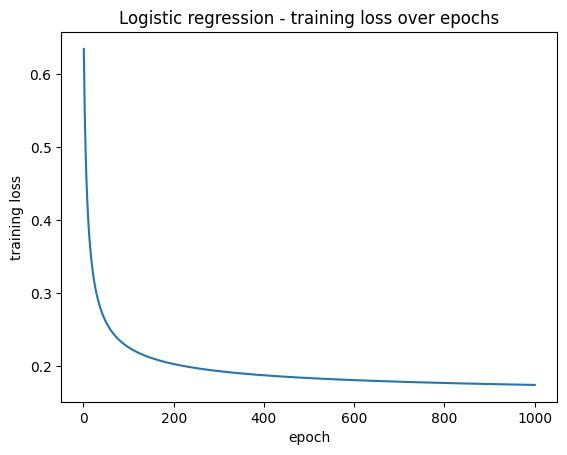

training accuracy (for all 1,500 emails): 0.939  Cross-validated accuracy: 0.933 gap: +0.007

---- Grid search for learning rate and epochs (CV mean, std) ---- 
learning_rate =  0.1, epochs =  500: mean = 0.922 std = 0.026
learning_rate =  0.1, epochs = 1000: mean = 0.928 std = 0.020
learning_rate =  0.1, epochs = 3000: mean = 0.933 std = 0.018
learning_rate =  0.5, epochs =  500: mean = 0.932 std = 0.018
learning_rate =  0.5, epochs = 1000: mean = 0.933 std = 0.017
learning_rate =  0.5, epochs = 3000: mean = 0.931 std = 0.021
learning_rate =  1.0, epochs =  500: mean = 0.933 std = 0.017
learning_rate =  1.0, epochs = 1000: mean = 0.930 std = 0.020
learning_rate =  1.0, epochs = 3000: mean = 0.931 std = 0.018

---- Tuning l2 (CV mean, std) ----
l2 =    0.0: mean = 0.933 std = 0.017
l2 = 0.0001: mean = 0.933 std = 0.017
l2 =  0.001: mean = 0.932 std = 0.018
l2 =   0.01: mean = 0.920 std = 0.022
l2 =    0.1: mean = 0.877 std = 0.027


In [9]:
import matplotlib.pyplot as plt
RUN_TESTING = True

if RUN_TESTING:
    print("---- Stage 3: logistic regression with default settings ----")
    lr_mean, lr_std, _ = cross_validate(LogisticRegressionClassifier, X, y, k=10)

    # A training curve, the loss on the training emails after each update, shows
    # whether gradient descent has converged (Russell and Norvig, 2022, §19.6.4, p.701).
    lr_all_emails = LogisticRegressionClassifier()
    lr_all_emails.train(X, y)
    loss_history = lr_all_emails.training_loss_history
    plt.plot(np.arange(1, len(loss_history) + 1), loss_history)
    plt.xlabel("epoch")
    plt.ylabel("training loss")
    plt.title("Logistic regression - training loss over epochs")
    plt.show()

    # Comparison of training accuracy with cross-validated accuracy.
    # A large gap may mean that the model is over-fitting. 
    train_accuracy = np.mean(lr_all_emails.predict(X) == y)
    print(f"training accuracy (for all 1,500 emails): {train_accuracy:.3f} "
          f" Cross-validated accuracy: {lr_mean:.3f} gap: {train_accuracy - lr_mean:+.3f}")

    # Hyperparameter tuning (Russell and Norvig, 2022, §19.4.4, pp.689-690).
    # Perform a grid search over the learning rate and epochs such 
    # that every combination is cross-validated. 
    # The learning rate and epochs control the progress of gradient descent. 
    # If learning rate is too small, or there are too few epochs, then training 
    # can stop before the minimum is reached. If the learning rate is too 
    # big then it could overshoot the minimum 
    # (Jurafsky and Martin, 2026, §4.6.2, p.106). 
    # If results show that every combination gives similar CV accuracy, then
    # using the default settings is fine. 
    print("\n---- Grid search for learning rate and epochs (CV mean, std) ---- ")
    for rate in [0.1, 0.5, 1.0]:
        for n_epochs in [500, 1000, 3000]:
            mean, std, _ = cross_validate(lambda: LogisticRegressionClassifier(learning_rate=rate, epochs=n_epochs),
                                        X, y, k=10, verbose=False)
            print(f"learning_rate = {rate:>4}, epochs = {n_epochs:>4}: mean = {mean:.3f} std = {std:.3f}")

    # L2 is tuned separately as, per Russell and Norvig (2022, §19.4.4, p.690),
    # independent hyperparameters "can be optimized separately" which helps reduce
    # the number of cross-validations needed from 45 to 14. L2 is independent as
    # it moves where the minimum of the loss is, while the learning rate and epochs 
    # only affect whether gradient descent reaches it. Values for l2 range from
    # no penalty to 0.1
    print("\n---- Tuning l2 (CV mean, std) ----") 
    for l2 in [0.0, 0.0001, 0.001, 0.01, 0.1]:
        mean, std, _ = cross_validate(lambda: LogisticRegressionClassifier(l2=l2),
                                    X, y, k=10, verbose=False)
        print(f"l2 = {l2:>6}: mean = {mean:.3f} std = {std:.3f}")

In [10]:
# ---- Stage 4: Neural Network (multilayer Perceptron with one hidden layer) ----
import numpy as np

def relu(z: np.ndarray) -> np.ndarray:
    """ 
    The rectified linear unit: ReLU(z) = max(0, z) (Russell and Norvig, 2022, §22.1.1, p.803;
    Jurafsky and Martin, 2026, §6.1, p.153). 

    A hidden unit with z <= 0 outputs 0 (it is switched off) and a unit with z > 0 passes z 
    through unchanged (it is switched on). The derivative of ReLU's output is thus 0 
    when the unit is off and 1 when it is on, even for very large z values. (Jurafsky 
    and Martin, 2026, §6.1, Figure 6.3 (b), p.154). 
    
    This derivative is why ReLU is selected as the activation function for the hidden layer 
    rather than sigmoid or tanh. These functions saturate for very high values of |z| 
    meaning their derivatives approach zero which is problematic for 
    backpropagation as the error reaching a unit's weights is multiplied by the activation 
    derivative. So saturated sigmoid or tanh units stop learning which is known as
    "the vanishing gradient problem". ReLU activation functions do not have this problem 
    as they pass the error through in full because for high values of z their gradient is 1 
    (Jurafsky and Martin, 2026, §6.1, p.154). 
    """
    return np.maximum(0.0, z)

def derivative_relu(z: np.ndarray) -> np.ndarray:
    """
    Calculate the derivative of the ReLU activation function for the hidden layer. 
    
    The derivative is 1 for z > 0 and otherwise 0. It is undefined at z = 0
    but 0 is used here. 
    """
    return (z > 0).astype(float)

class FeedforwardClassifier:
    """
    A feedforward neural network, also known as a multilayer perceptron 
    (Bishop, 2006, §5.1, p.229), with one hidden layer of ReLU units and a
    sigmoid output, that is trained by full-batch gradient descent using backpropagation. 

    Architecture: 
        54 keyword features -> hidden_units ReLU units -> 1 sigmoid output

    Forward pass:
        (1) z1 = X @ W1 + b1                - the hidden pre-activations, shape (n, hidden_units)
        (2) h = relu(z1)                    - the hidden activations, shape (n, hidden_units)
        (3) p = sigmoid(h @ W2 + b2)        - P(spam | keywords), shape (n, )

        Equation (3) above has the same structure as the Stage 3 logistic regression
        p = sigmoid(X @ w + b), but here h (learned features) replaces X (raw keywords)
        (Jurafsky and Martin, 2026, §6.3, Eq.6.8 and 6.12, pp.158-159). Since W1 is trained
        by gradient descent, each hidden unit learns to respond to the combination 
        of keywords that minimises the loss (Jurafsky and Martin, 2026, §6.2, pp.155-157). 

    Loss:
        The loss is calculated using mean cross-entropy with an added
        L2 weight-decay penalty (like in Stage 3) but here the penalty, 
        lambda/2 * (||W1||^2 + ||W2||^2), is applied to the weights of both
        layers but not the biases (Russell and Norvig, 2022, §22.5.3, p.822). 
        Weight decay is used as Krogh and Hertz (1992) showed that it improves 
        generalisation of neural networks. 
    
    Backpropagation:
        Here the chain rule is applied to each layer, starting with the output layer
        (Bishop, 2006, §5.3.1, pp.241-245). 

        grad_z2 = (p - y) / n                                               - output error, prediction minus label
        grad_W2 = h.T @ grad_z2, grad_b2 = sum(grad_z2)                     - gradients of the output layer
        grad_h  = outer(grad_z2, W2)                                        - dE/dh: rate of change of the loss 
                                                                              with respect to each hidden activation
        grad_z1 = grad_h * derivative_relu(z1)                              - dE/dz1: grad_h propagated back through ReLU, 
                                                                              so zero for units that are off                           
        grad_W1 = X.T @ grad_z1, grad_b1 = sum(grad_z1, axis=0)             - gradients of the hidden layer

    Attributes:
        W1, b1: the hidden layer weights, shape (54, hidden_units) and biases, shape (hidden_units, )
        W2, b2: the output layer weights, shape (hidden_units, ) and bias, a float
        training_loss_history: the training loss() after each epoch, shape (epochs, )
    """

    def __init__(self, hidden_units: int = 16, learning_rate: float = 0.5,
                 epochs: int = 1000, l2: float = 0.0, seed: int = 0):
        """ 
        Args:
            hidden_units:       the number of ReLU units (hidden layer). Following Bishop (2006, §5.5, p.256), 
                                larger numbers of units are tested and overfitting is controlled with weight 
                                decay instead of minimising the number of units. 
            learning_rate:      the step size alpha in w <- w - alpha * gradient. 
            epochs:             the number of full-batch gradient descent steps. 
            l2:                 the weight-decay strength lambda, applied to W1 and W2 but not to
                                b1 and b2.
            seed:               the seed used for the random initialisation of W1 so the results can be 
                                reproduced. 

        Default settings:
            The default settings are set based on the results from running stage4_testing(). 
            Cross-validating accuracy for hidden_units {8, 16, 32} and learning_rate {0.1, 0.5}
            results in accuracy scores of 0.929 to 0.933, and for l2 {0, 1e-4, 1e-3, 1e-2} scores of 
            0.931 to 0.934, all within one standard error (0.023 / sqrt(10) ≈ 0.007) of the defaults 
            (0.931 ± 0.023). Different starting seeds were also tested {0, 1, 2} but they all 
            resulted in similar accuracy scores of 0.927 to 0.933, also within one standard error
            of the default seed. l2 = 0.1 did result in a lower accuracy than the rest of the values, 
            at 0.889. Since no setting did significantly better than the original defaults, these remain 
            as: hidden_units = 16, learning_rate = 0.5, epochs = 1000, l2 = 0.0 and seed = 0. 
        """
        self.hidden_units = hidden_units
        self.learning_rate = learning_rate
        self.epochs = epochs
        self.l2 = l2
        self.seed = seed

    # ---- Initialisation -----

    def initialise_parameters(self, n_features: int) -> None:
        """
        Sets the starting values for W1, b1, W2, and b2.

        W1 is made up of small random values, such that all the hidden units start out 
        different. If units started with the same weights they would compute the same
        output, get the same gradient and so remain identical, which would operate like
        one hidden unit rather than multiple hidden_units. Goodfellow, Bengio and 
        Courville (2016, §8.4, p.297) refer to this as "breaking symmetry" and describe 
        it as "perhaps the only property known with complete certainty" that 
        initialisation needs. 

        The scale of these random values follows He et al. (2015, §2.2, Eq.10). They 
        use a zero-mean Gaussian with standard deviation sqrt(2 / fan_in) where fan_in
        is the number of inputs to the layer. This scale preserves the signal size
        across ReLU layers. 
        
        Biases start at 0 (He et al., 2015). W2 also starts at 0 as the output layer 
        only has one unit so there is no symmetry that needs breaking. 

        Args:
            n_features: the number of inputs to the hidden layer (54 for this data)
        """
        rng = np.random.default_rng(self.seed)   # seeded random generator, for reproducibility of W1
        # zero-mean Gaussian scale (He et al., 2015, §2.2, Eq.10)
        self.W1 = rng.normal(0.0, np.sqrt(2.0 / n_features), size=(n_features, self.hidden_units))
        self.b1 = np.zeros(self.hidden_units)
        self.W2 = np.zeros(self.hidden_units)
        self.b2 = 0.0

    # ---- Forward pass -----

    def forward(self, X: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
        """ 
        The forward pass runs the inputs through the hidden layer and then
        the output layer. This follows equations (1) to (3) from the class docstring
        (Jurafsky and Martin, 2026, §6.3, Eq.6.8 and 6.12, pp.158-159).

        The output uses sigmoid, rather than the ReLU used by the hidden layer, so 
        that p is a probability (see sigmoid() in Stage 3). Russell and Norvig 
        (2022, §22.2.2, p.809) state that for Boolean classification with a 
        single output, "we commonly use a sigmoid output layer". 

        Returns p but also z1 and h as they are needed for backpropagation. 

        Args:
            X: features, shape (n, 54)

        Returns:
            z1: hidden pre-activations, shape (n, hidden_units)
            h: hidden activations, shape (n, hidden_units)
            p: P(spam | keywords), shape (n, )
        """
        z1 = X @ self.W1 + self.b1
        h = relu(z1)
        # Sigmoid is used for the output so p is a probability between 0 and 1
        p = sigmoid(h @ self.W2 + self.b2)
        return z1, h, p

    def predict_spam_prob(self, X:np.ndarray) -> np.ndarray:
        """ 
        Calculates P(spam | keywords) for each email by running the forward pass
        and returning p from its final output.

        Args:
            X: features, shape (n, 54)

        Returns:
            P(spam | keywords) per email, shape (n, )
        """
        # forward(0) returns tuple of (z1, h, p), here we select p
        return self.forward(X.astype(float))[2]

    def loss(self, X:np.ndarray, y:np.ndarray) -> float:
        """ 
        The mean cross-entropy, as in Stage 3, plus the L2 penalty 
        lambda/2 * (||W1||^2 + ||W2||^2), as described in this class
        docstring. 

        p gets clipped to [1e-12, 1 - 1e-12] before the logs are taken,
        which acts as a floating point guard (see 
        LogisticRegressionClassifier.loss() for more details). 

        Args:
            X: features, shape (n, 54)
            y: labels, 0 = ham and 1 = spam, shape (n, )

        Returns:
            the loss, float 
        """
        p = np.clip(self.predict_spam_prob(X), 1e-12, 1 - 1e-12)
        cross_entropy = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))
        penalty = 0.5 * self.l2 * (np.sum(self.W1 ** 2) + np.sum(self.W2 ** 2))
        return float(cross_entropy + penalty)

    # ---- Backward pass -----
    def gradient(self, X: np.ndarray, y: np.ndarray
                 ) -> tuple[np.ndarray, np.ndarray, np.ndarray, float]:
        """ 
        The analytic gradient of loss() with respect to all parameters, calculated
        for all emails at once using backpropagation (Bishop, 2006, §5.3.1, 
        pp.241-245). 

        First a forward pass calculates z1, h and p and then a backward pass computes 
        the gradients. The backward pass is needed as the hidden layer weights affect 
        the loss indirectly, via a sequence of steps (W1 -> z1 -> h -> z2 -> p -> loss). 
        By the chain rule, the derivative of the sequence is the product of the 
        derivative of each step (Jurafsky and Martin, 2026, §6.6.4, Eq.6.31-6.32, p.171).

        The backward pass starts at the output error and moves towards the input, 
        taking one step at a time. Each step involves multiplying the gradient passed back 
        to it from the later step with its own local derivative, and this result is then passed
        on to the next earlier step. This process repeats until the input is reached
        (Jurafsky and Martin, 2026, §6.6.4, Figure 6.16, p.172). 
        
        See the Backpropagation part of this class docstring for the steps. 

        Args:
            X: features, shape (n, 54)
            y: labels, 0 = ham and 1 = spam, shape (n, )
        
        Returns:
            grad_W1, grad_b1, grad_W2, grad_b2, their shapes are the same as the parameters 
            they are for (see Attributes part of this class docstring). 
        """
        n_emails = len(y)
        z1, h, p = self.forward(X)

        # The gradient of the output layer. This is Stage 3's gradient() but with h in place of X.
        # grad_z2 takes the average over all emails, once.
        grad_z2 = (p - y) / n_emails                        # shape (n, )
        grad_W2 = h.T @ grad_z2 + self.l2 * self.W2         # shape (hidden_units, )
        grad_b2 = float(grad_z2.sum())

        # The gradient of the hidden layer: applying the chain rule, starting with
        # grad_z2 which is multiplied by the local derivative of each step moving backwards.
        grad_h = np.outer(grad_z2, self.W2)                 # step z2 -> h: derivative is W2
        grad_z1 = grad_h * derivative_relu(z1)              # step h -> z1: derivative is 1 for switched on units
                                                            # and 0 for switched off units
        grad_W1 = X.T @ grad_z1 + self.l2 * self.W1         # step z1 -> W1: derivative is X
        grad_b1 = grad_z1.sum(axis=0)                       # step z1 -> b1: derivative is 1

        return grad_W1, grad_b1, grad_W2, grad_b2
    
    # ---- Training -----
    def train(self, X: np.ndarray, y: np.ndarray) -> None:
        """ 
        Fits W1, b1, W2 and b2 by full-batch gradient descent, minimising loss().

        The loss here is not convex, unlike the Stage 3 loss, so gradient descent is no longer
        guaranteed to reach the global minimum. Goodfellow, Bengio and Courville 
        (2016, §8.2.2, pp.281-282) note that there can be small neural networks that
        have local minima with higher cost than the global minimum. Since this network 
        is small and different seeds could result in different local minima,
        stage4_testing() runs tests to assess the impact of seed selection.

        Args:
            X: features, shape (n, 54)
            y: labels, 0 = ham and 1 = spam, shape (n, )
        """
        X = X.astype(float)
        y = y.astype(float)
        self.initialise_parameters(X.shape[1])      # selects the number of features, 54 for this data

        # create an array with one slot per epoch to 
        # record the loss after each gradient step.
        self.training_loss_history = np.empty(self.epochs)

        for epoch in range(self.epochs):
            grad_W1, grad_b1, grad_W2, grad_b2 = self.gradient(X, y)

            # This is the learning step. The gradient points in the direction 
            # where the loss increases the fastest, so we move in the opposite direction.
            self.W1 -= self.learning_rate * grad_W1
            self.b1 -= self.learning_rate * grad_b1
            self.W2 -= self.learning_rate * grad_W2
            self.b2 -= self.learning_rate * grad_b2

            # Captures the loss after each step. 
            self.training_loss_history[epoch] = self.loss(X, y)

    # ---- Prediction -----

    def predict(self, X: np.ndarray) -> np.ndarray:
        """ 
        Predicts ham (0) or spam (1) for each of the emails. 

        Prediction is spam if P(spam | keywords) > 0.5 and ham if <= 0.5
        (Jurafsky and Martin, 2026, §4.3, p.97). 

        An email with a probability of exactly 0.5 is predicted to be ham
        as wrongly blocking a non-spam email is generally worse for a user than 
        letting a spam email through (Androutsopoulos et al., 2000, §2, p.11). 

        Args:
            X: features, shape (n, 54)
        
        Returns:
            predicted labels, ham = 0 and spam = 1, shape (n, )
        """ 
        return (self.predict_spam_prob(X) > 0.5).astype(int)

def check_feedforward_gradient(model: FeedforwardClassifier, X: np.ndarray, y: np.ndarray,
                               parameter_name: str, index: tuple, h: float = 1e-5
                               ) -> tuple[float, float, float, bool]:
    """ 
    Checks the gradient is correct by comparing the analytic gradient 
    for one parameter with a numerical estimate. This is an extension
    of the Stage 3 check_gradient(), to all four of the parameter arrays
    (W1, b1, W2, b2). 

    Like in Stage 3, an incorrect gradient here would not raise an error. 
    The model would still be trained and there may be no noticeable issues 
    with the output or accuracy. This check helps to confirm that this 
    implementation can be trusted (Bishop, 2006, §5.3.3, pp.246-247). 

    Kinks can cause this check to be inaccurate and ReLU does have a kink
    at z = 0. If shifting a parameter by +/- h causes the z1 of any hidden
    unit to cross 0, then the numeric estimate is no longer comparable with 
    the analytic gradient (CS231n, n.d.b, Gradient checks). This can be 
    detected by recording and comparing which hidden units are on as the parameter
    is shifted up by +h with when they are shifted down by -h. 
    If these states do not match then a kink was crossed and this should be tracked 
    separately as it does not mean the implementation is necessarily wrong. 
    Due to kinks the relative error can be tolerated up to 1e-4 and like in Stage 3, 
    any error above 1e-2 is likely incorrect (CS231n, n.d.b, Gradient checks). 

    Args:
        model: a trained FeedforwardClassifier
        X: features, shape (n, 54)
        y: labels, 0 = ham and 1 = spam, shape (n, )
        parameter_name: "W1", "b1", "W2" or "b2"
        index: position in the array 
        h: the size of the adjustment made to the parameters; 1e-5 follows CS231n (n.d.b, Gradient checks). 

    Returns:
        analytic: analytic gradient for the given parameter
        numeric: numeric gradient, which is the central difference estimate for the given parameter
        relative_error: |analytic gradient - numeric gradient| / max(|analytic|, |numeric|)
        kink_crossed: Boolean that is True if a hidden unit switched on or off as the parameter was being adjusted by +h and -h
    """
    X = X.astype(float)
    y = y.astype(float)
    # create a dictionary of parameter gradients, with their names as keys
    gradient_lookup = dict(zip(("W1", "b1", "W2", "b2"), model.gradient(X, y)))
    analytic = float(np.asarray(gradient_lookup[parameter_name])[index])

    parameter_array = getattr(model, parameter_name)
    trained_value = float(np.asarray(parameter_array)[index])   # tracked so we can reference and restore it

    def set_parameter(value: float) -> None:
        """
        Sets the parameter that is being checked to value.
        
        Since b2 is a float it is overwritten directly, no index position needed.
        """
        if parameter_name == "b2":
            model.b2 = value
        else:
            parameter_array[index] = value

    set_parameter(trained_value + h)                            # adjust the parameter up by +h
    loss_add = model.loss(X, y)
    units_on_add = model.forward(X)[0] > 0                      # which units are switched on (z1 > 0) for +h
    set_parameter(trained_value - h)                            # adjust the parameter down by -h
    loss_subtract = model.loss(X, y)
    units_on_subtract = model.forward(X)[0] > 0                 # which units are switched on (z1 > 0) for -h
    set_parameter(trained_value)                                # set the adjusted parameter value back to its original value

    numeric = (loss_add - loss_subtract) / (2 * h)
    relative_error = abs(analytic - numeric) / max(abs(analytic), abs(numeric), 1e-20)
    kink_crossed = bool(np.any(units_on_add != units_on_subtract))
    return analytic, numeric, relative_error, kink_crossed



In [11]:
RUN_TESTING = True

if RUN_TESTING:
    print("---- Stage 4: gradient check ----")
    # Gradient check run on a partly trained model with l2 = 0.0 (isolate the 
    # cross-entropy part) and l2 = 0.01 (to check the l2 term), as was done 
    # in Stage 3 (CS231n, n.d.b, Gradient checks). 

    for l2 in [0.0, 0.01]: 
        model_to_check = FeedforwardClassifier(epochs=200, l2=l2)
        model_to_check.train(X, y)
        # Based on inspect_data(): keyword 24 is strongest ham indicator keyword, 
        # keyword 40 is never found in spam and keyword 51 is the strongest spam 
        # indicator. All of W1, b1, W2 and b2 are tested as checks are run for: 
        # one weight per keyword for the hidden layer, one weight in the output layer, 
        # one hidden bias and one output bias. 
        # The hidden units used are arbitrarily chosen as: 0, 5, 15, 7 and 3. 
        for parameter_name, index in [("W1", (24, 0)), ("W1", (40, 5)), ("W1", (51, 15)),
                                       ("b1", (7, )), ("W2", (3, )) , ("b2", ())]:
            analytic, numeric, relative_error, kink = check_feedforward_gradient(
                model_to_check, X, y, parameter_name, index)
            # Due to ReLU kinks the relative error can be tolerated up to 1e-4 (CS231n, n.d.b). 
            if kink:
                conclusion = "kink was crossed, numerical estimate is not comparable with analytic gradient."
            elif relative_error <= 1e-4:
                conclusion = "pass"
            elif relative_error > 1e-2:
                conclusion = "fail"
            else:
                conclusion = "investigate"
            print(f"l2 = {l2}, {parameter_name}{index}: analytic = {analytic:+.6e} "
                  f"numeric = {numeric:+.6e} relative error = {relative_error:.1e} {conclusion}") 

---- Stage 4: gradient check ----
l2 = 0.0, W1(24, 0): analytic = +1.789220e-05 numeric = +1.789219e-05 relative error = 1.1e-07 pass
l2 = 0.0, W1(40, 5): analytic = -2.135337e-05 numeric = -2.135337e-05 relative error = 7.9e-08 pass
l2 = 0.0, W1(51, 15): analytic = -5.143699e-04 numeric = -5.143699e-04 relative error = 2.7e-09 pass
l2 = 0.0, b1(7,): analytic = -8.162626e-04 numeric = -7.019849e-04 relative error = 1.4e-01 kink was crossed, numerical estimate is not comparable with analytic gradient.
l2 = 0.0, W2(3,): analytic = +6.136651e-04 numeric = +6.136651e-04 relative error = 6.5e-10 pass
l2 = 0.0, b2(): analytic = -2.910992e-04 numeric = -2.910992e-04 relative error = 3.0e-09 pass
l2 = 0.01, W1(24, 0): analytic = -5.628681e-04 numeric = -5.628681e-04 relative error = 3.9e-09 pass
l2 = 0.01, W1(40, 5): analytic = -1.814500e-03 numeric = -1.814500e-03 relative error = 1.8e-09 pass
l2 = 0.01, W1(51, 15): analytic = +4.425434e-04 numeric = +4.425434e-04 relative error = 9.7e-10 pas

---- Stage 4 feedforward model using default settings  (hidden_units = 16, learning_rate = 0.5, epochs = 1000, and l2 = 0) ---- 
fold 1/10: fold accuracy = 0.934 
train 1349, test= 151
fold 2/10: fold accuracy = 0.881 
train 1349, test= 151
fold 3/10: fold accuracy = 0.921 
train 1349, test= 151
fold 4/10: fold accuracy = 0.947 
train 1349, test= 151
fold 5/10: fold accuracy = 0.960 
train 1350, test= 150
fold 6/10: fold accuracy = 0.933 
train 1350, test= 150
fold 7/10: fold accuracy = 0.953 
train 1351, test= 149
fold 8/10: fold accuracy = 0.906 
train 1351, test= 149
fold 9/10: fold accuracy = 0.946 
train 1351, test= 149
fold 10/10: fold accuracy = 0.926 
train 1351, test= 149
mean = 0.931   std = 0.023


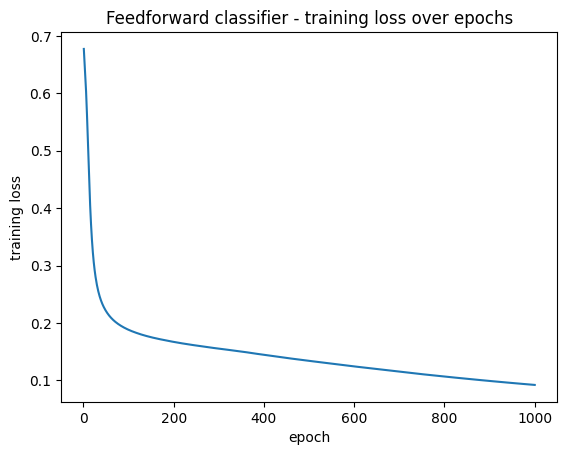

training accuracy (for all 1,500 emails): 0.969 Cross-validated accuracy: 0.931 gap: +0.039

---- A grid search for hidden units and learning rate (CV mean, std) ----
hidden_units =  8, learning_rate =  0.1: mean = 0.931 std = 0.019
hidden_units =  8, learning_rate =  0.5: mean = 0.933 std = 0.016
hidden_units = 16, learning_rate =  0.1: mean = 0.930 std = 0.018
hidden_units = 16, learning_rate =  0.5: mean = 0.931 std = 0.023
hidden_units = 32, learning_rate =  0.1: mean = 0.929 std = 0.017
hidden_units = 32, learning_rate =  0.5: mean = 0.931 std = 0.019

---- Tuning l2 (CV mean, std) ----
l2 =    0.0: mean = 0.931 std = 0.023
l2 = 0.0001: mean = 0.932 std = 0.023
l2 =  0.001: mean = 0.934 std = 0.023
l2 =   0.01: mean = 0.931 std = 0.017
l2 =    0.1: mean = 0.889 std = 0.028

---- Check effect of Seed on the local minimum reached (CV mean, std) ----
seed = 0: mean = 0.931 std = 0.023
seed = 1: mean = 0.933 std = 0.017
seed = 2: mean = 0.927 std = 0.016

 Time to run stage4_testing()

In [12]:
# ---- Stage 4: Testing ----
# The experiments below justify the default settings for FeedforwardClassifier. 
# They do not need to be run to use the classifier so it is not advised 
# to have RUN_TESTING = True by default as they add unnecessary steps that slow 
# down the notebook runtime (takes ~47 seconds to run which is well over 
# the run time of 30 seconds).
# Set RUN_TESTING = True to rerun the experiments and reproduce the Stage 4 results. 
RUN_TESTING = True

import matplotlib.pyplot as plt
import time

def stage4_testing(X: np.ndarray, y:np.ndarray) -> None:
    """ 
    Runs the experiments that justify the choice of default settings for FeedforwardClassifier.

    Stage 4 follows a similar sequence of tests to Stage 3 for comparability. 

    The experiments:
    1. Default settings                 - Cross-validate accuracy with the default settings of:
                                          hidden_units = 16, learning_rate = 0.5, epochs = 1000,
                                          and l2 = 0. 
    2. Training curve                   - Plots the loss on the training emails after each update, to  
                                          confirm if gradient descent has converged 
                                          (Russell and Norvig, 2022, §19.6.4, p.701). The training accuracy
                                          is also compared with the cross-validated accuracy to assess if 
                                          over-fitting could be occurring. 
    3. Grid search                      - Perform a grid search over the hidden_units {8, 16, 32}
                                          and learning_rate {0.1, 0.5}, comparing the cross-validated 
                                          accuracy for each combination of settings. 
    4. l2 tuning                        - Cross-validate accuracy for different l2 settings: 
                                          {0, 1e-4, 1e-3, 1e-2, 0.1}. L2 is tuned separately 
                                          (like in Stage 3) as per Russell and Norvig (2022, §19.4.4, p.690) 
                                          independent hyperparameters "can be optimized separately". 
    5. Seed check                       - Cross-validate accuracy for different starting seeds {0, 1, 2}
                                          to assess effect of the seed on the local minimum reached.
                                          This only affects the initialisation step and not the folds tested. 
    
    The cross_validate() function from Stage 1 is used for all of the cross validation steps.
    This ensures a fair comparison between Stages 2, 3 and 4 as the folds are the same for each stage.            

    Args:
        X: features, shape (n, 54)                    
        y: labels, 0 = ham and 1 = spam, shape (n, )                     
    """
    start = time.perf_counter()

    # Experiment 1 - Default settings:
    print("---- Stage 4 feedforward model using default settings "
          " (hidden_units = 16, learning_rate = 0.5, epochs = 1000, and l2 = 0) ---- ")
    ff_mean, ff_std, _ = cross_validate(FeedforwardClassifier, X, y, k=10)

    # Experiment 2 - Training curve:
    # A training curve, the loss on the training emails after each update, shows
    # whether gradient descent has converged (Russell and Norvig, 2022, §19.6.4, p.701).
    ff_all_emails = FeedforwardClassifier()
    ff_all_emails.train(X, y)
    loss_history = ff_all_emails.training_loss_history
    plt.plot(np.arange(1, len(loss_history) + 1), loss_history)
    plt.xlabel("epoch")
    plt.ylabel("training loss")
    plt.title("Feedforward classifier - training loss over epochs")
    plt.show()

    # Comparison of training accuracy with cross-validated accuracy.
    # A large gap may mean that the model is over-fitting. 
    train_accuracy = np.mean(ff_all_emails.predict(X) == y)
    print(f"training accuracy (for all 1,500 emails): {train_accuracy:.3f} "
          f"Cross-validated accuracy: {ff_mean:.3f} gap: {train_accuracy - ff_mean:+.3f}")

    # Experiment 3 - Grid search:
    print("\n---- A grid search for hidden units and learning rate (CV mean, std) ----")
    for n_units in [8, 16, 32]:
        for rate in [0.1, 0.5]:
            mean, std, _ = cross_validate(
                lambda: FeedforwardClassifier(hidden_units=n_units, learning_rate=rate),
                X, y, k=10, verbose=False)
            print(f"hidden_units = {n_units:>2}, learning_rate = {rate:>4}: "
                  f"mean = {mean:.3f} std = {std:.3f}")
    
    # Experiment 4 - l2 tuning:
    print("\n---- Tuning l2 (CV mean, std) ----") 
    for l2 in [0.0, 0.0001, 0.001, 0.01, 0.1]:
        mean, std, _ = cross_validate(lambda: FeedforwardClassifier(l2=l2),
                                    X, y, k=10, verbose=False)
        print(f"l2 = {l2:>6}: mean = {mean:.3f} std = {std:.3f}")

    # Experiment 5 - Seed check:
    print("\n---- Check effect of Seed on the local minimum reached (CV mean, std) ----") 
    for seed in [0, 1, 2]:
        mean, std, _ = cross_validate(lambda: FeedforwardClassifier(seed=seed),
                                    X, y, k=10, verbose=False)
        print(f"seed = {seed}: mean = {mean:.3f} std = {std:.3f}")

    # timing
    print(f"\n Time to run stage4_testing() was {time.perf_counter() - start:.0f} seconds")

if RUN_TESTING:
    stage4_testing(X, y)

In [ ]:
# ---- Stage 5.1: Model comparison and final model selection ----
# Change RUN_TESTING = True to run the comparison. This is not needed
# to use the submitted classifier and would cost unnecessary additional time 
# (~4 seconds) if this cell is also run. 
RUN_TESTING = True

import time

def compare_models(X: np.ndarray, y:np.ndarray, k: int = 10) -> dict:
    """ 
    Cross-validates each model from Stages 1, 2, 3 and 4, using the same k folds
    since cross_validate() uses the same seed (seed = 0) for each model.
    This means that the models can be compared fold by fold, as well as by their means.

    With 10-fold cross-validation any two of the training sets share 8 out of 10 folds, 
    so their fold accuracies are not independent. A paired t-test is thus not done, 
    following Dietterich (1998; cited by Raschka, 2018, §4.10, p.44), who discourages it 
    because of this overlap of training sets.

    The submitted classifier is the one with the highest CV mean, unless there is
    a simpler model that is within one standard error of it, then this simpler model
    is chosen. This is the "one-standard error method" (Breiman et al., 1984; cited 
    by Raschka, 2018, §3.10, p.32).

    Args:
        X: features, shape (n, 54)                    
        y: labels, 0 = ham and 1 = spam, shape (n, )
        k: number of folds
    
    Returns:
        dictionary of fold accuracies (array with shape (k, )) with model names as the keys
    """
    candidate_models = {
        "Baseline - Most common class": MostCommonClass,
        "Bernoulli Naïve Bayes (alpha=1, Laplace add-one smoothing)": NaiveBayesClassifier,
        "Logistic Regression (lr=0.5, 1000 epochs, l2=0)": LogisticRegressionClassifier,
        "Feedforward Neural Network (16 ReLU hidden units, lr=0.5, 1000 epochs, l2=0)": FeedforwardClassifier,
    }

    model_results = {}
    rows = []
    for model_name, make_model in candidate_models.items():
        mean, std, per_fold = cross_validate(make_model, X, y, k=k, verbose=False)
        model_results[model_name] = per_fold

        # Train the model once on all of the emails to measure time 
        # taken to train and the training accuracy.
        # The training accuracy is "optimistically biased" since the model has already
        # seen all of the emails before. The gap between training accuracy and CV
        # accuracy estimates the level of over-fitting (Raschka, 2018, §1.2-1.3, pp.6-7).
        start = time.perf_counter()
        model = make_model()
        model.train(X, y)
        time_to_train = time.perf_counter() - start
        train_accuracy = float(np.mean(model.predict(X) == y))
        accuracy_gap = train_accuracy - mean

        rows.append((model_name, mean, std, std / np.sqrt(k), train_accuracy, accuracy_gap, time_to_train))

    # Markdown summary table
    print("| Model | CV mean | CV std | Std error CV mean | Training accuracy | Accuracy gap | Time to train (s) |")
    print("|---|---|---|---|---|---|---|")
    for model_name, mean, std, std_error_cv_mean, training_accuracy, accuracy_gap, time_to_train in rows:
        print(f"| {model_name} | {mean:.3f} | {std:.3f} | {std_error_cv_mean:.3f} "
              f"| {training_accuracy:.3f} | {accuracy_gap:+.3f} | {time_to_train:.2f} |")

    # Rank the models based on their CV mean to find the top two performing models. 
    ranked_models = sorted(rows, key=lambda row: row[1], reverse=True)
    best_model, best_mean, _, best_std_error, *_ = ranked_models[0]
    second_best_model, second_best_mean, _, second_best_std_error, *_ = ranked_models[1]
    print(f"\nTop two models based on CV mean:")
    print(f"  {best_model} {best_mean:.3f} ± {best_std_error:.3f} "
          f"compared to {second_best_model} {second_best_mean:.3f} ± {second_best_std_error:.3f}")

    # Fold-by-fold comparison of the CV accuracy for the two top performing models. 
    performance_diff = model_results[second_best_model] - model_results[best_model]
    print(f"\nFold-by-fold accuracy comparison: {second_best_model} - {best_model}:")
    print("  per fold:", np.array2string(performance_diff, precision=3))
    print(f"  mean accuracy difference = {performance_diff.mean():+.3f}, "
          f"std of accuracy differences = {performance_diff.std():.3f}, "
          f"std error of mean accuracy difference = {performance_diff.std() / np.sqrt(k):.3f}")
    print(f"  {second_best_model} is better on {int((performance_diff > 0).sum())} folds, "
          f"{best_model} is better on {int((performance_diff < 0).sum())} folds, "
          f"the models are tied on {int((performance_diff == 0).sum())} folds")

    # Apply one-standard error method if needed
    within_one_std_error = [row[0] for row in ranked_models[1:] if best_mean - row[1] <= best_std_error]
    print(f"\nThe highest CV mean: {best_model} ({best_mean:.3f})")
    if within_one_std_error:
        print(f"The CV accuracy scores of {best_model} and {'; '.join(within_one_std_error)} "
             f"are within one standard error of each other,\n"
             f"so the simplest model is selected as the classifier for submission." )
    else:
        print(f"There are no other models that are within one standard error of {best_model},\n "
              f"so it is selected as the classifier for submission.")

    return model_results

if RUN_TESTING:
    start = time.perf_counter()
    comparison_of_results = compare_models(X, y)
    print(f"\nTime taken to run compare_models() was {time.perf_counter() - start:.0f} seconds.")

| Model | CV mean | CV std | Std error CV mean | Training accuracy | Accuracy gap | Time to train (s) |
|---|---|---|---|---|---|---|
| Baseline - Most common class | 0.609 | 0.001 | 0.000 | 0.609 | -0.000 | 0.00 |
| Bernoulli Naïve Bayes (alpha=1, Laplace add-one smoothing) | 0.885 | 0.037 | 0.012 | 0.889 | +0.004 | 0.00 |
| Logistic Regression (lr=0.5, 1000 epochs, l2=0) | 0.933 | 0.017 | 0.005 | 0.939 | +0.007 | 0.07 |
| Feedforward Neural Network (16 ReLU hidden units, lr=0.5, 1000 epochs, l2=0) | 0.931 | 0.023 | 0.007 | 0.969 | +0.039 | 0.31 |

Top two models based on CV mean:
  Logistic Regression (lr=0.5, 1000 epochs, l2=0) 0.933 ± 0.005 compared to Feedforward Neural Network (16 ReLU hidden units, lr=0.5, 1000 epochs, l2=0) 0.931 ± 0.007

Fold-by-fold accuracy comparison: Feedforward Neural Network (16 ReLU hidden units, lr=0.5, 1000 epochs, l2=0) - Logistic Regression (lr=0.5, 1000 epochs, l2=0):
  per fold: [-0.007 -0.02  -0.007  0.013  0.02   0.013 -0.013 -0.013  0.007 -0.01

In [ ]:
# ---- Stage 5.2: Precision, recall and the cost of each error type ----
# Accuracy treats both kinds of mistake the same, but in spam filtering they are not
# equal: a ham email that gets blocked (a false positive) is generally worse for a
# user than a spam email that gets through (a false negative)
# (Androutsopoulos et al., 2000, §2, p.11). This stage reports the confusion matrix
# and metrics that separate the two error types, so the evaluation reflects the
# nature of the problem and not only the metric used for model selection.
# Model selection in Stage 5.1 was still made on accuracy as this is what the
# assignment grades.
# Set RUN_TESTING = True to reproduce the results (~4 seconds).
RUN_TESTING = True

def out_of_fold_predictions(model_to_test: Callable[[], object], X: np.ndarray,
                            y: np.ndarray, seed: int = 0, k: int = 10) -> np.ndarray:
    """
    Collects one prediction per email from stratified k-fold cross-validation.

    Each email is predicted exactly once, by the model trained on the other k-1 folds,
    so the predictions are for unseen emails. Using the same seed and k as
    cross_validate() means the folds are identical to Stages 2 to 5.

    Args:
        model_to_test: a class or function that makes a new untrained model.
        X: features, shape (n, 54)
        y: labels, shape (n, )
        seed: random seed for the fold shuffle, matches cross_validate()
        k: the number of folds

    Returns:
        predicted labels for every email, shape (n, )
    """
    rng = np.random.default_rng(seed)
    folds = strat_k_fold(y, k, rng)
    predictions = np.empty(len(y), dtype=int)

    for test_rows in folds:
        train_rows = np.setdiff1d(np.arange(len(y)), test_rows)
        model = model_to_test()
        model.train(X[train_rows], y[train_rows])
        predictions[test_rows] = model.predict(X[test_rows])
    return predictions

def classification_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> dict:
    """
    Builds the confusion matrix and calculates the metrics that separate the
    two error types, treating spam (1) as the positive class.

    Confusion matrix counts:
        TP: spam predicted as spam          FN: spam predicted as ham (spam gets through)
        FP: ham predicted as spam (ham is blocked)      TN: ham predicted as ham

    Metrics (Manning, Raghavan and Schütze, 2008, §8.3, Eq.8.1-8.6, pp.142-144;
    false positive rate from §8.4, p.149):
        precision = TP / (TP + FP)      share of the emails flagged as spam that really are spam
        recall    = TP / (TP + FN)      share of the spam emails that were caught
        F1        = 2 * precision * recall / (precision + recall)   harmonic mean of the two
        false positive rate = FP / (FP + TN)    share of ham emails that were wrongly blocked.
            This is the error that matters most to a user (Androutsopoulos et al., 2000, §2, p.11).

    Args:
        y_true: labels, 0 = ham and 1 = spam, shape (n, )
        y_pred: predicted labels, shape (n, )

    Returns:
        dictionary of the counts and metrics
    """
    tp = int(np.sum((y_pred == 1) & (y_true == 1)))
    fp = int(np.sum((y_pred == 1) & (y_true == 0)))
    fn = int(np.sum((y_pred == 0) & (y_true == 1)))
    tn = int(np.sum((y_pred == 0) & (y_true == 0)))

    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    false_positive_rate = fp / (fp + tn) if fp + tn > 0 else 0.0
    accuracy = (tp + tn) / len(y_true)

    return {"TP": tp, "FP": fp, "FN": fn, "TN": tn, "accuracy": accuracy,
            "precision": precision, "recall": recall, "f1": f1,
            "false_positive_rate": false_positive_rate}

if RUN_TESTING:
    start = time.perf_counter()
    candidate_models = {
        "Bernoulli Naïve Bayes": NaiveBayesClassifier,
        "Logistic Regression (submitted)": LogisticRegressionClassifier,
        "Feedforward Neural Network": FeedforwardClassifier,
    }

    print("| Model | Accuracy | Precision | Recall | F1 | Ham wrongly blocked (FP rate) | FP | FN |")
    print("|---|---|---|---|---|---|---|---|")
    for model_name, make_model in candidate_models.items():
        m = classification_metrics(y, out_of_fold_predictions(make_model, X, y))
        print(f"| {model_name} | {m['accuracy']:.3f} | {m['precision']:.3f} | {m['recall']:.3f} "
              f"| {m['f1']:.3f} | {m['false_positive_rate']:.3f} ({m['FP']} of {m['FP'] + m['TN']} ham) "
              f"| {m['FP']} | {m['FN']} |")

    # The confusion matrix for the submitted model, in full. 
    m = classification_metrics(y, out_of_fold_predictions(LogisticRegressionClassifier, X, y))
    print("\nConfusion matrix for Logistic Regression (rows = actual, columns = predicted):")
    print(f"{'':>12} {'pred ham':>10} {'pred spam':>10}")
    print(f"{'actual ham':>12} {m['TN']:>10} {m['FP']:>10}")
    print(f"{'actual spam':>12} {m['FN']:>10} {m['TP']:>10}")
    print(f"\nTime taken to run Stage 5.2 was {time.perf_counter() - start:.0f} seconds.")

| Model | Accuracy | Precision | Recall | F1 | Ham wrongly blocked (FP rate) | FP | FN |
|---|---|---|---|---|---|---|---|
| Bernoulli Naïve Bayes | 0.885 | 0.889 | 0.807 | 0.846 | 0.065 (59 of 914 ham) | 59 | 113 |
| Logistic Regression (submitted) | 0.933 | 0.926 | 0.899 | 0.913 | 0.046 (42 of 914 ham) | 42 | 59 |
| Feedforward Neural Network | 0.931 | 0.917 | 0.904 | 0.911 | 0.053 (48 of 914 ham) | 48 | 56 |

Confusion matrix for Logistic Regression (rows = actual, columns = predicted):
               pred ham  pred spam
  actual ham        872         42
 actual spam         59        527

Time taken to run Stage 5b was 5 seconds.


In [ ]:
# ----Classifier for submission----
# Logistic regression is submitted as the classifier based on the 
# Stage 5.1 model comparison results. It had the best CV accuracy 
# at 0.933 ± 0.005 std error. The feedforward neural network's
# CV accuracy was within one standard error of it and since
# logistic regression is simpler, it was chosen instead of the neural
# network (Breiman et al., 1984; cited by Raschka, 2018, §3.10, p.32). 
# Stage 5.2 confirms this model choice as logistic regression has the
# lowest false positive rate, which is the more costly error type for
# a spam classifier (Androutsopoulos et al., 2000, §2, p.11), as well as the 
# highest precision and F1 score compared to the other models. 
# The original default settings are used as none of the additional
# tested settings outperformed them in Stage 3 tuning. 
# The final model is trained on all 1,500 emails, which is possible
# since cross-validation has already given the accuracy estimate
# (Raschka, 2018, §3.3, p.23).
def create_classifier() -> LogisticRegressionClassifier:
    """ 
    Trains the final Logistic regression classifier on all of the labelled emails.

    Returns:
        a trained Logistic regression classifier with learning_rate = 0.5,
        epochs = 1000 and l2 = 0 (no regularisation applied)
    """
    data = np.vstack([training_spam, testing_spam])
    X_all, y_all = split_x_and_y(data)

    classifier = LogisticRegressionClassifier(learning_rate =0.5, epochs =1000, l2 =0.0)
    classifier.train(X_all, y_all)
    return classifier

classifier = create_classifier()

### Accuracy Estimate
In the cell below there is a function called `my_accuracy_estimate()` which returns `0.5`. Before you submit the assignment, write your best guess for the accuracy of your classifier into this function, as a percentage between `0` and `1`. So if you think you will get 80% of inputs correct, return the value `0.8`. This will form a small part of the marking criteria for the assignment, to encourage you to test your own code.

In [16]:
# I use the logistic regression cross-validation mean as my accuracy estimate. 
# It may underestimate the final model accuracy, as each CV fold was 
# trained on only ~1,350 emails while the final model is trained on 
# all 1,500 (Raschka, 2018, §3.3, p.23).
def my_accuracy_estimate():
    return 0.933

# References:

Androutsopoulos, I., Koutsias, J., Chandrinos, K.V., Paliouras, G. and Spyropoulos, C.D., 2000. An evaluation of naive Bayesian anti-spam filtering. In: G. Potamias, V. Moustakis and M. van Someren, eds. *Proceedings of the workshop on machine learning in the new information age, 11th European Conference on Machine Learning (ECML 2000)*, 2000, Barcelona. Barcelona: s.n., pp.9-17.

Bishop, C.M., 2006. *Pattern recognition and machine learning*. New York: Springer.

CS231n, n.d. a. *Optimization: stochastic gradient descent* [Online]. Stanford, Calif.: Stanford University. Available from: https://cs231n.github.io/optimization-1/ [Accessed 1 November 2026].

CS231n, n.d. b. *Neural networks part 3: learning and evaluation* [Online]. Stanford, Calif.: Stanford University. Available from: https://cs231n.github.io/neural-networks-3/ [Accessed 1 November 2026].

Goodfellow, I., Bengio, Y. and Courville, A., 2016. *Deep learning*. Cambridge, Mass.: MIT Press.

He, K., Zhang, X., Ren, S. and Sun, J., 2015. Delving deep into rectifiers: surpassing human-level performance on ImageNet classification. *Proceedings of the IEEE International Conference on Computer Vision (ICCV)*, 7-13 December 2015, Santiago. Piscataway, N.J.: IEEE, pp.1026-1034.

Jurafsky, D. and Martin, J.H., 2026. *Speech and language processing: an introduction to natural language processing, computational linguistics, and speech recognition with language models* [Online]. 3rd ed. draft, 19 August 2026. Available from: https://web.stanford.edu/~jurafsky/slp3/ [Accessed 1 November 2026].

Kohavi, R., 1995. A study of cross-validation and bootstrap for accuracy estimation and model selection. *Proceedings of the 14th International Joint Conference on Artificial Intelligence (IJCAI-95)*, 20-25 August 1995, Montreal. San Mateo, Calif.: Morgan Kaufmann, pp.1137-1143.

Krogh, A. and Hertz, J.A., 1992. A simple weight decay can improve generalization. In: J.E. Moody, S.J. Hanson and R.P. Lippmann, eds. *Advances in neural information processing systems 4 (NIPS 1991)*, 2-5 December 1991, Denver. San Mateo, Calif.: Morgan Kaufmann, pp.950-957.

Manning, C.D., Raghavan, P. and Schütze, H., 2008. *Introduction to information retrieval*. Cambridge: Cambridge University Press.

McCallum, A. and Nigam, K., 1998. A comparison of event models for naive Bayes text classification. *AAAI-98 Workshop on Learning for Text Categorization*, 26-27 July 1998, Madison, Wis. Menlo Park, Calif.: AAAI Press, pp.41-48.

Murphy, K.P., 2012. *Machine learning: a probabilistic perspective*. Cambridge, Mass.: MIT Press.

Ng, A.Y. and Jordan, M.I., 2001. On discriminative vs. generative classifiers: a comparison of logistic regression and naive Bayes. In: T.G. Dietterich, S. Becker and Z. Ghahramani, eds. *Advances in neural information processing systems 14 (NIPS 2001)*, 3-8 December 2001, Vancouver. Cambridge, Mass.: MIT Press, pp.841-848.

Raschka, S., 2018. Model evaluation, model selection, and algorithm selection in machine learning. *arXiv* [Online]. Available from: https://arxiv.org/abs/1811.12808 [Accessed 1 November 2026].

Russell, S.J. and Norvig, P., 2022. *Artificial intelligence: a modern approach*. 4th ed., global edition. Harlow: Pearson.

Write all of the code for your classifier above this cell.

### Testing Details
Your classifier will be tested against some hidden data from the same source as the original. The accuracy (percentage of classifications correct) will be calculated, then benchmarked against common methods. At the very high end of the grading scale, your accuracy will also be compared to the best submissions from other students (in your own cohort and others!). Your estimate from the cell above will also factor in, and you will be rewarded for being close to your actual accuracy (overestimates and underestimates will be treated the same).

#### Test Cell
The following code will run your classifier against the provided test data. To enable it, set the constant `SKIP_TESTS` to `False`.

The original skeleton code above classifies every row as ham, but once you have written your own classifier you can run this cell again to test it. So long as your code sets up a variable called `classifier` with a method called `predict`, the test code will be able to run. 

Of course you may wish to test your classifier in additional ways, but you *must* ensure this version still runs before submitting.

**IMPORTANT**: you must set `SKIP_TESTS` back to `True` before submitting this file!

In [17]:
SKIP_TESTS = True

if not SKIP_TESTS:
    testing_spam = np.loadtxt(open("data/testing_spam.csv"), delimiter=",").astype(int)
    test_data = testing_spam[:, 1:]
    test_labels = testing_spam[:, 0]

    predictions = classifier.predict(test_data)
    accuracy = np.count_nonzero(predictions == test_labels)/test_labels.shape[0]
    print(f"Accuracy on test data is: {accuracy}")

In [18]:
import sys
import pathlib

fail = False;

success = '\033[1;32m[✓]\033[0m'
issue = '\033[1;33m[!]'
error = '\033[1;31m\t✗'

#######
##
## Skip Tests check.
##
## Test to ensure the SKIP_TESTS variable is set to True to prevent it slowing down the automarker.
##
#######

if not SKIP_TESTS:
    fail = True;
    print("{} \'SKIP_TESTS\' is incorrectly set to False.\033[0m".format(issue))
    print("{} You must set the SKIP_TESTS constant to True in the cell above.\033[0m".format(error))
else:
    print('{} \'SKIP_TESTS\' is set to true.\033[0m'.format(success))

#######
##
## File Name check.
##
## Test to ensure file has the correct name. This is important for the marking system to correctly process the submission.
##
#######
    
p3 = pathlib.Path('./spamclassifier.ipynb')
if not p3.is_file():
    fail = True
    print("{} The notebook name is incorrect.\033[0m".format(issue))
    print("{} This notebook file must be named spamclassifier.ipynb\033[0m".format(error))
else:
    print('{} The notebook name is correct.\033[0m'.format(success))

#######
##
## Create classifier function check.
##
## Test that checks the create_classifier function exists. The function should train the classifier and return it so that it can be evaluated by the marking system.
##
#######

if "create_classifier" not in dir():
    fail = True;
    print("{} The create_classifier function has not been defined.\033[0m".format(issue))
    print("{} Your code must include a create_classifier function as described in the coursework specification.\033[0m".format(error))
    print("{} If you believe you have, \'restart & run-all\' to clear this error.\033[0m".format(error))
else:
    print('{} The create_classifier function has been defined.\033[0m'.format(success))

#######
##
## Classifier variable check.
##
## Test that checks the classifier variable exists. The marking system will use this variable to make predictions based on a set of random features you have not seen. Your score will be based on how well your classifier predicts the hidden labels.
##
#######

if 'classifier' not in vars():
    fail = True;
    print("{} The classifer variable has not been defined.\033[0m".format(issue))
    print("{} Your code must create a variable called \'classifier\' as described in the coursework specification.\033[0m".format(error))
    print("{} This variable should contain the trained classifier you have created.\033[0m".format(error))
else:
    print('{} The classifer variable has been correctly defined.\033[0m'.format(success))

#######
##
## Accuracy Estimation check.
##
## Test that checks the accuracy estimation function exists and is a reasonable value. This is a requirement of the coursework specification and is used by the marking system when generating your final grade.
##
#######

if "my_accuracy_estimate" not in dir():
    fail = True;
    print("{} The my_accuracy_estimate function has not been defined.\033[0m".format(issue))
    print("{} Your code must include a my_accuracy_estimate function as described in the coursework specification.\033[0m".format(error))
    print("{} If you believe you have, \'restart & run-all\' to clear this error.\033[0m".format(error))
else:
    if my_accuracy_estimate() == 0.5:
        print("{} my_accuracy_estimate function warning.\033[0m".format(issue))
        print("{} my_accuracy_estimate function returns a value of 0.5 - Your classifier is no better than random chance.\033[0m".format(error))
        print("{} Are you sure this is correct.\033[0m".format(error))
    else:
        print('{} The my_accuracy_estimate function has been defined correctly.\033[0m'.format(success))

#######
##
## Test set check.
##
## Test that checks your classifier actually works. The calls made here are the same made by the automarker - albeit with different data. If your work fails this test it will score 0 in the automarker.
##
#######

try:
    testing_spam = np.loadtxt(open("data/testing_spam.csv"), delimiter=",").astype(int)
    test_data = testing_spam[:, 1:]
    test_labels = testing_spam[:, 0]
    
    try:
        predictions = classifier.predict(test_data)
        accuracy = np.count_nonzero(predictions == test_labels)/test_labels.shape[0]
        print('{0} Success running test set - Accuracy was {1:.2f}%.\033[0m'.format(success, (accuracy*100)))
    except Exception as e:
        fail = True
        print("{} Error running test set.\033[0m".format(issue))
        print("{} Your code produced the following error. This error will result in a zero from the automarker, please fix.\033[0m".format(error))
#         print("{} {}\033[0m".format(error, e))
        print(e)
except:
    sys.stderr.write("Unable to run one test as the file \'data/testing_spam.csv\' could not be found.")

#######
##
## Final Summary
##
## Prints the final results of the submission tests.
##
#######

if fail:
    sys.stderr.write("Your submission is not ready! Please read and follow the instructions above.")
else:
    print("\033[1m\n\n")
    print("╔═══════════════════════════════════════════════════════════════╗")
    print("║                        Congratulations!                       ║")
    print("║                                                               ║")
    print("║            Your work meets all the required criteria          ║")
    print("║                   and is ready for submission.                ║")
    print("╚═══════════════════════════════════════════════════════════════╝")
    print("\033[0m")
    

[✓] 'SKIP_TESTS' is set to true.
[✓] The notebook name is correct.
[✓] The create_classifier function has been defined.
[✓] The classifer variable has been correctly defined.
[✓] The my_accuracy_estimate function has been defined correctly.
[✓] Success running test set - Accuracy was 93.40%.



╔═══════════════════════════════════════════════════════════════╗
║                        Congratulations!                       ║
║                                                               ║
║            Your work meets all the required criteria          ║
║                   and is ready for submission.                ║
╚═══════════════════════════════════════════════════════════════╝



In [19]:
# This is a test cell. Please do not modify or delete.